# 01 - Exploration du jeu de données Task08_HepaticVessel

Dans ce notebook, j'explore les données utilisées dans le projet : contenu de l'archive officielle,
géométrie des volumes, intensités, labels, puis je vérifie la séparation au niveau patient et le
prétraitement. Toutes les valeurs affichées sont calculées sur les fichiers réellement téléchargés.

Prérequis : `scripts/download_data.py`, `scripts/prepare_data.py` et `scripts/inspect_dataset.py`
ont été exécutés.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 140)
from src.utils import load_config, resolve
cfg = load_config("configs/data.yaml")
raw_dir = resolve(cfg["dataset"]["raw_dir"])

## 1. Description officielle

Le fichier `dataset.json` fourni avec l'archive décrit la tâche, la modalité, les labels et la licence.

In [2]:
from src.data.msd import read_dataset_json
info = read_dataset_json(raw_dir)
for key in ("name", "description", "reference", "licence", "release", "modality", "labels", "numTraining", "numTest"):
    print(f"{key:>12} : {info.get(key)}")

        name : HepaticVessel
 description : Hepatic Vessels and Tumour Segmentation
   reference : Memorial Sloan Kettering Cancer Center
     licence : CC-BY-SA 4.0
     release : 1.1 14/08/2018
    modality : {'0': 'CT'}
      labels : {'0': 'background', '1': 'Vessel', '2': 'Tumour'}
 numTraining : 303
     numTest : 140


## 2. Géométrie de tous les volumes

Les dimensions et l'espacement des voxels ont été lus dans les en-têtes NIfTI des 443 volumes
(303 annotés, 140 de test non annotés) par requêtes partielles sur l'archive, sans télécharger les images.

In [3]:
headers = pd.read_csv("results/metrics/dataset_headers.csv")
print(headers.groupby("subset")[["nx", "ny", "nz", "sx_mm", "sy_mm", "sz_mm"]].describe().T.round(3))
print("Tailles dans le plan :", headers.groupby(["nx", "ny"]).size().to_dict())
print("Épaisseurs de coupe (volumes annotés) :", headers[headers.subset == "imagesTr"]["sz_mm"].round(2).value_counts().head(8).to_dict())

subset       imagesTr  imagesTs
nx    count   303.000   140.000
      mean    512.000   512.000
      std       0.000     0.000
      min     512.000   512.000
      25%     512.000   512.000
      50%     512.000   512.000
      75%     512.000   512.000
      max     512.000   512.000
ny    count   303.000   140.000
      mean    512.000   512.000
      std       0.000     0.000
      min     512.000   512.000
      25%     512.000   512.000
      50%     512.000   512.000
      75%     512.000   512.000
      max     512.000   512.000
nz    count   303.000   140.000
      mean     69.703    75.343
      std      43.876    49.140
      min      24.000    24.000
      25%      41.000    41.000
      50%      49.000    49.000
      75%      93.500   118.500
      max     181.000   251.000
sx_mm count   303.000   140.000
      mean      0.805     0.801
      std       0.097     0.097
      min       0.568     0.633
      25%       0.732     0.739
      50%       0.799     0.784
      75

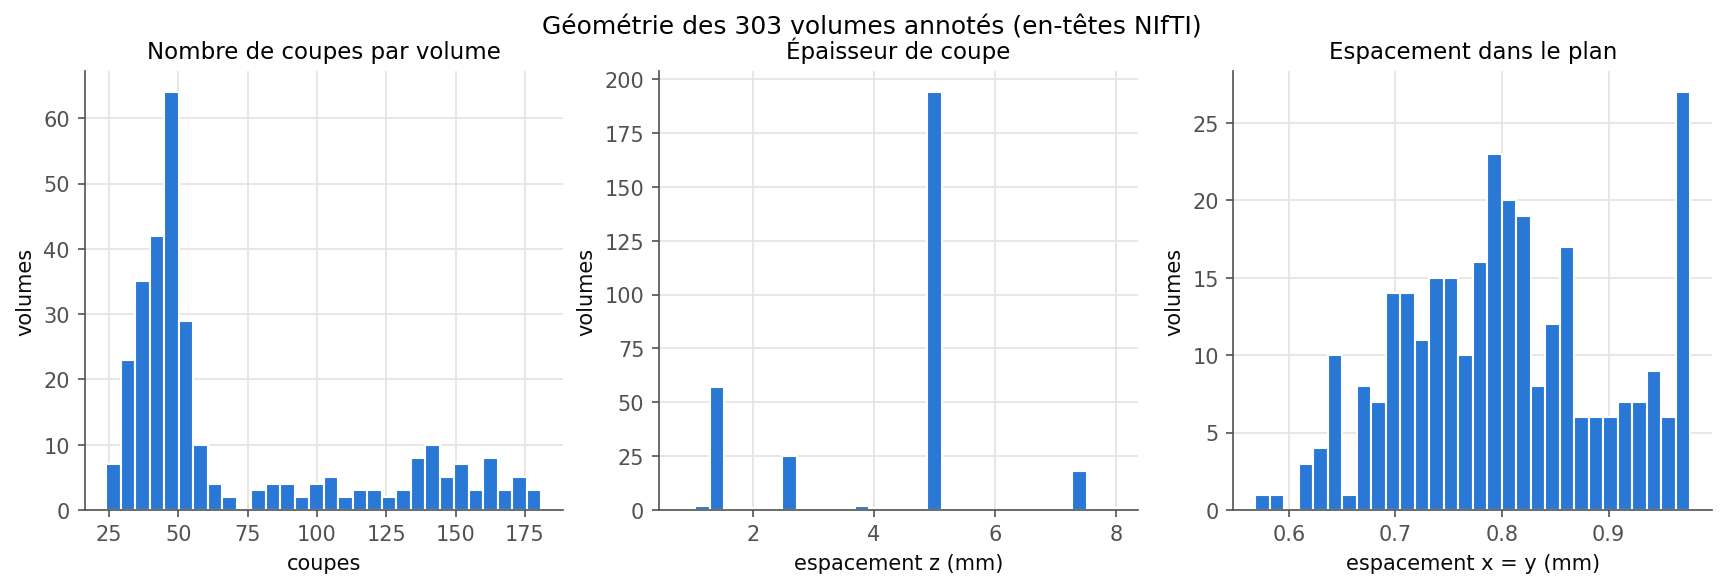

In [4]:
display(Image("results/figures/dataset/geometrie_volumes.png"))

Les 443 volumes ont tous des coupes de 512 x 512 pixels, mais leur nombre de coupes et leur
espacement varient beaucoup. Parmi les volumes annotés, 64 % ont des coupes de 5 mm et 19 % des
coupes de 1,5 mm ; l'espacement dans le plan va de 0,57 à 0,98 mm. Un même vaisseau n'occupe donc
pas le même nombre de pixels d'un patient à l'autre, et les volumes sont très anisotropes (rapport
médian de 5,8 entre l'épaisseur de coupe et la taille du pixel). C'est une des raisons pour
lesquelles l'approche principale est en 2D, et pour lesquelles le U-Net 3D ne sous-échantillonne
d'abord que dans le plan.

## 3. Intensités et labels des volumes téléchargés

Les statistiques suivantes portent sur le sous-ensemble téléchargé (voir `configs/data.yaml`).

In [5]:
insp = pd.read_csv("results/metrics/dataset_inspection.csv")
print(insp.groupby("split").size().to_dict())
cols = ["nz", "sz_mm", "sx_mm", "hu_min", "hu_max", "vessel_hu_mean", "tumour_hu_mean",
        "vessel_fraction", "tumour_fraction", "vessel_ml", "tumour_ml", "slices_with_vessel", "vessel_components"]
insp[cols].describe().T.round(4)

{'test': 20, 'train': 40, 'val': 8}


,count,mean,std,min,25%,50%,75%,max
nz,68.0,67.0735,44.9475,26.0000,40.0000,47.0000,60.5000,181.0000
sz_mm,68.0,4.3978,1.6764,0.8000,4.6875,5.0000,5.0000,8.0000
sx_mm,68.0,0.8197,0.0998,0.6113,0.7471,0.8145,0.9180,0.9766
hu_min,68.0,-1024.0000,0.0000,-1024.0000,-1024.0000,-1024.0000,-1024.0000,-1024.0000
hu_max,68.0,1817.5588,706.0804,1147.0000,1323.5000,1478.0000,2229.7500,3072.0000
vessel_hu_mean,68.0,157.1120,28.8999,96.0013,137.2274,156.5387,175.8987,212.9793
tumour_hu_mean,68.0,91.1927,24.3544,43.4368,75.3603,91.0181,104.9914,155.8302
vessel_fraction,68.0,0.0010,0.0005,0.0002,0.0007,0.0009,0.0013,0.0025
tumour_fraction,68.0,0.0045,0.0095,0.0000,0.0003,0.0012,0.0027,0.0460
vessel_ml,68.0,36.5122,14.8889,11.1358,26.1529,35.5297,44.7161,86.7521


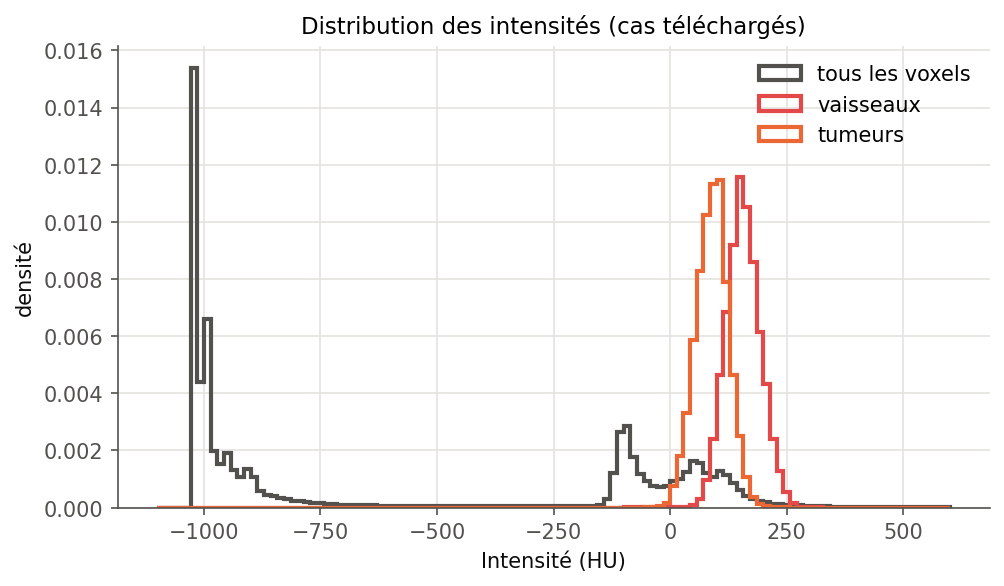

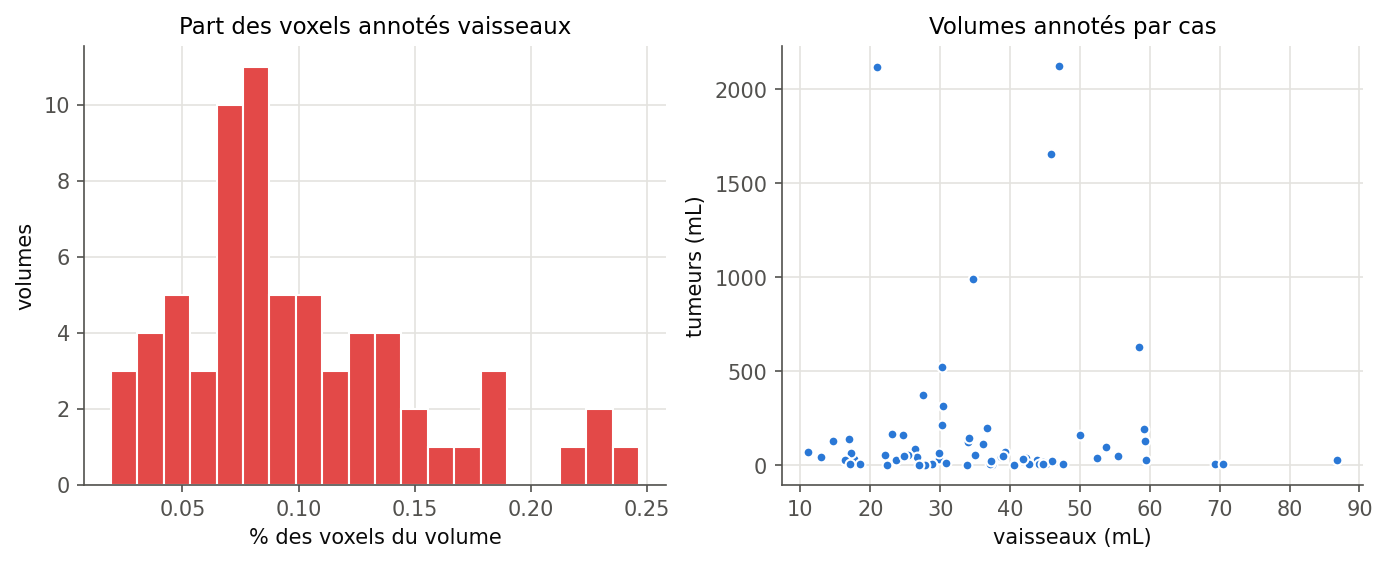

In [6]:
display(Image("results/figures/dataset/histogrammes_intensites.png"))
display(Image("results/figures/dataset/statistiques_labels.png"))

Les vaisseaux (157 HU en moyenne) sont plus brillants que les tumeurs (91 HU) et que le
parenchyme hépatique, mais les distributions se recouvrent : l'intensité seule ne suffit pas à
séparer les classes. Les vaisseaux représentent environ 0,1 % des voxels, d'où un fort
déséquilibre entre les classes. Le volume de tumeur varie de moins de 1 mL à plus de 2 L selon les
patients. Les cas de test ont en moyenne un peu plus de vaisseaux annotés (43,6 mL) que les cas
d'entraînement (34,7 mL), ce qui reste dans la variabilité observée entre patients.

## 4. Exemples de coupes et de masques

Coupes axiale, coronale et sagittale d'un volume, avec le masque de référence (rouge : vaisseaux,
jaune : tumeurs). Le rapport d'aspect tient compte de l'espacement réel des voxels.

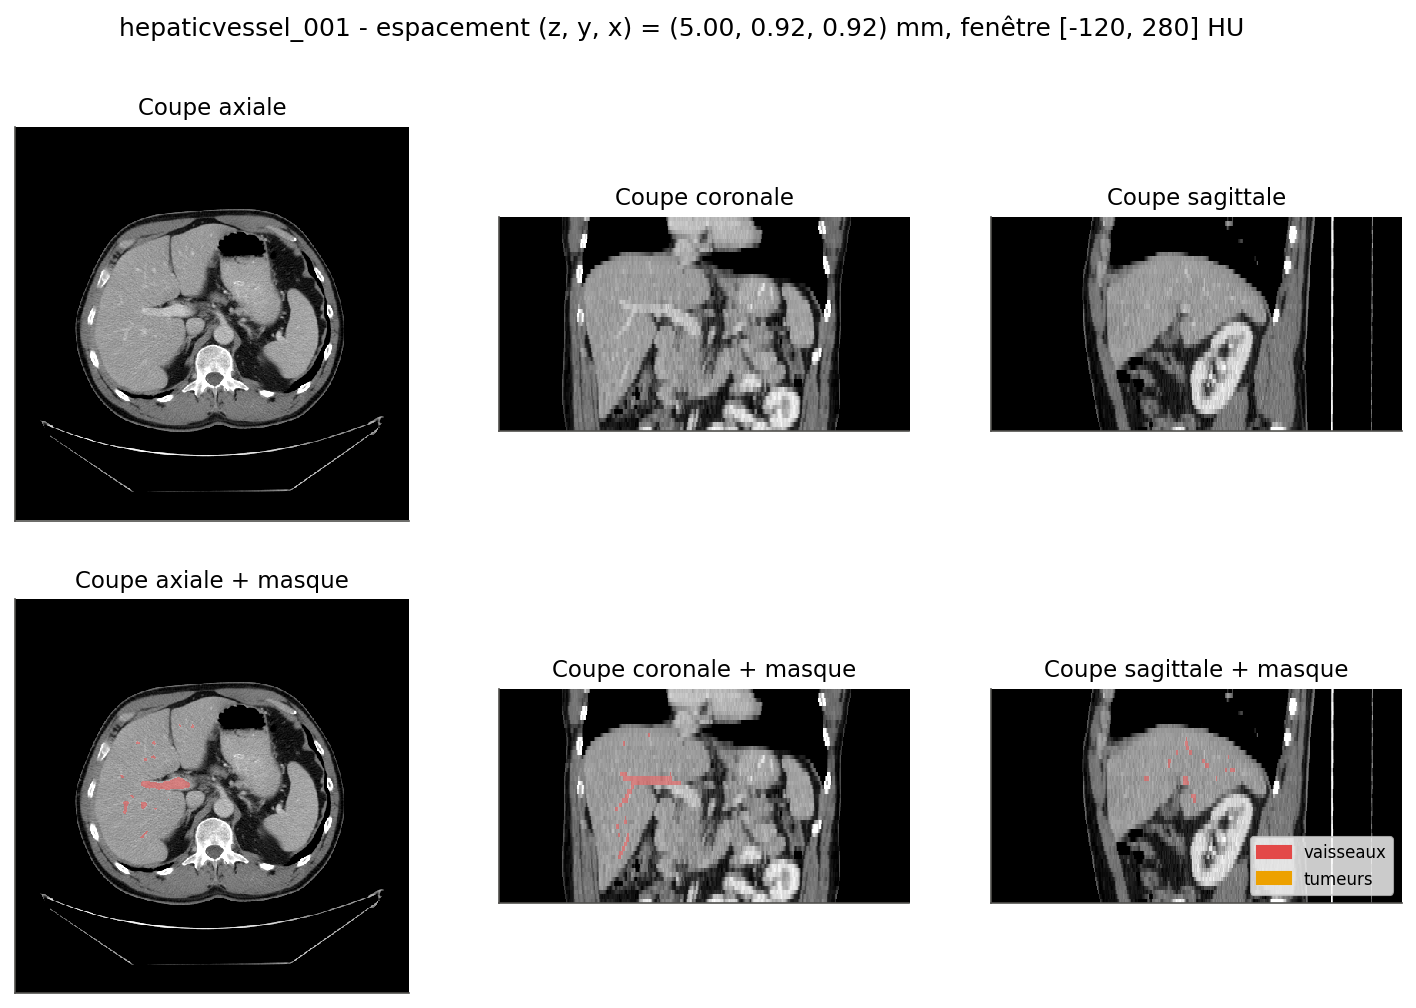

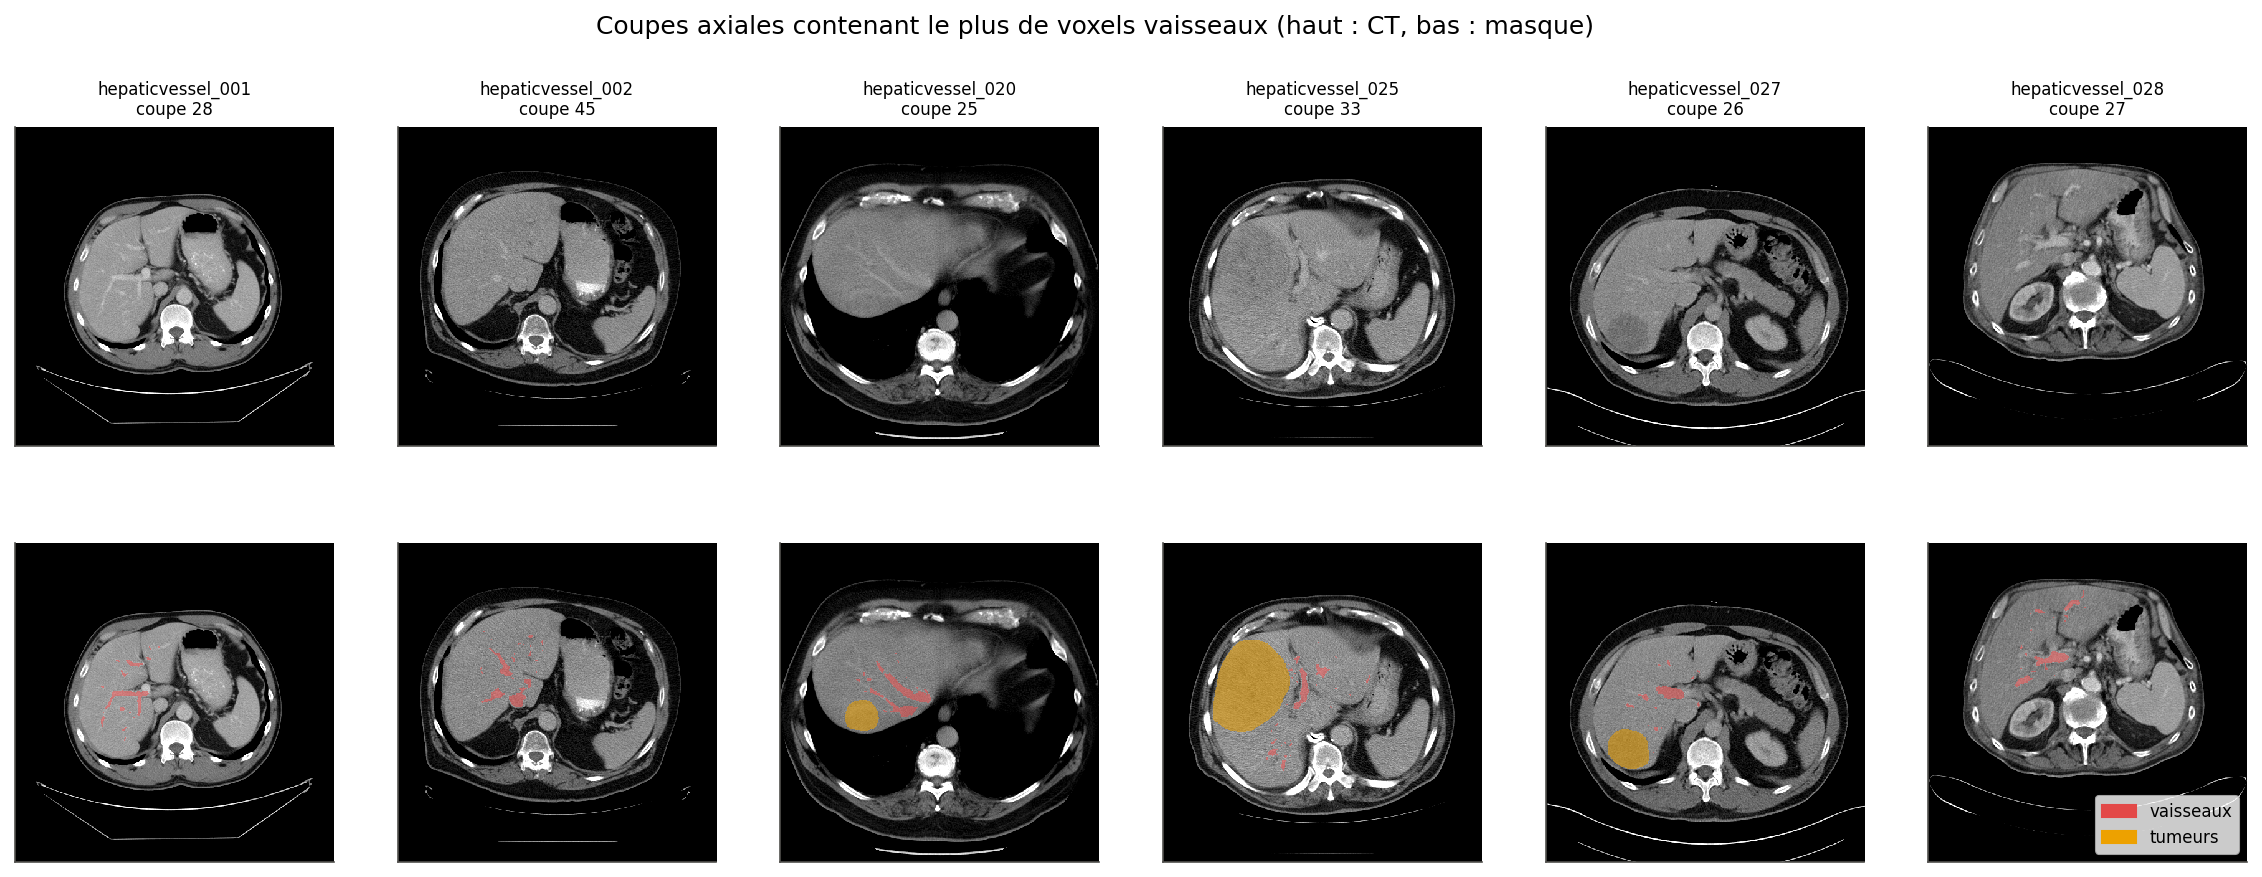

In [7]:
for path in sorted(Path("results/figures/dataset").glob("vues_*.png"))[:1]:
    display(Image(str(path)))
display(Image("results/figures/dataset/galerie_coupes.png"))

## 5. Vérifications de chargement

Pour chaque cas, `load_case` vérifie que l'image et le masque ont les mêmes dimensions et la même
matrice affine, et que le masque ne contient que les labels 0, 1 et 2. Les volumes sont réorientés
en RAS+ sans interpolation.

In [8]:
from src.data.msd import load_case, list_cases
from src.data.splits import load_split, check_disjoint
split = load_split(resolve(cfg["split"]["file"]), "subset")
full = load_split(resolve(cfg["split"]["file"]), "full")
check_disjoint(split); check_disjoint(full)
print("Séparation complète :", {k: len(v) for k, v in full.items()}, "| sous-ensemble utilisé :", {k: len(v) for k, v in split.items()})
print("Cas disponibles localement :", len(list_cases(raw_dir)))
case = load_case(raw_dir, split["train"][0])
print(case.case_id, "forme (Z, H, W) =", case.image.shape, "| espacement (mm) =", tuple(round(s, 3) for s in case.spacing),
      "| orientation d'origine =", "".join(case.original_axcodes), "| labels =", np.unique(case.label))

Séparation complète : {'train': 212, 'val': 45, 'test': 46} | sous-ensemble utilisé : {'train': 40, 'val': 8, 'test': 20}
Cas disponibles localement : 68


hepaticvessel_245 forme (Z, H, W) = (65, 512, 512) | espacement (mm) = (2.5, 0.744, 0.744) | orientation d'origine = RAS | labels = [0 1 2]


## 6. Prétraitement

Les intensités sont tronquées aux percentiles 0,5 et 99,5 des voxels annotés de l'ensemble
d'entraînement, puis centrées-réduites (même schéma que nnU-Net pour le CT).

{'clip_low': 8.0, 'clip_high': 240.0, 'mean': 101.82, 'std': 48.23, 'n_voxels': 2171407}


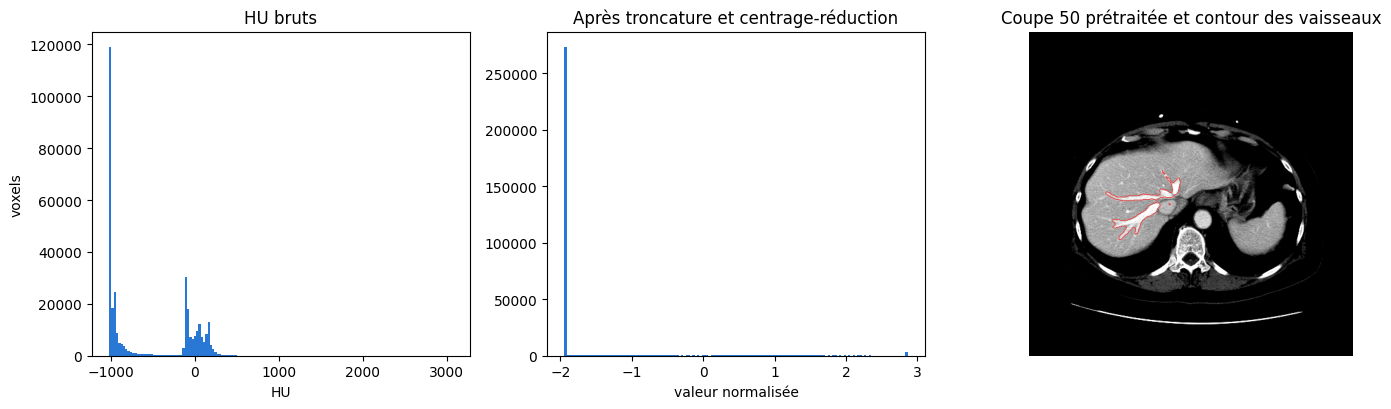

In [9]:
from src.preprocessing.pipeline import load_processed
stats = json.loads(Path(cfg["preprocessing"]["stats_file"]).read_text())
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in stats.items() if k != "train_cases"})
proc = load_processed(resolve(cfg["preprocessing"]["processed_dir"]) / case.case_id)
z = int(np.argmax((proc["label"] == 1).sum(axis=(1, 2))))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].hist(case.image.ravel()[::50], bins=150, color="#2a78d6"); axes[0].set(title="HU bruts", xlabel="HU", ylabel="voxels")
axes[1].hist(np.asarray(proc["image"]).ravel()[::50].astype(float), bins=150, color="#2a78d6")
axes[1].set(title="Après troncature et centrage-réduction", xlabel="valeur normalisée")
axes[2].imshow(np.asarray(proc["image"][z], float), cmap="gray")
axes[2].contour(np.asarray(proc["label"][z]) == 1, levels=[0.5], colors=["#e34948"], linewidths=0.6)
axes[2].set_title(f"Coupe {z} prétraitée et contour des vaisseaux"); axes[2].axis("off")
plt.tight_layout(); plt.show()

## 7. Patches d'entraînement

Les patches de 192 x 192 pixels sont tirés à 67 % autour d'un voxel annoté. L'image et le masque
subissent la même transformation spatiale ; l'image ci-dessous permet de vérifier leur alignement
après augmentation.

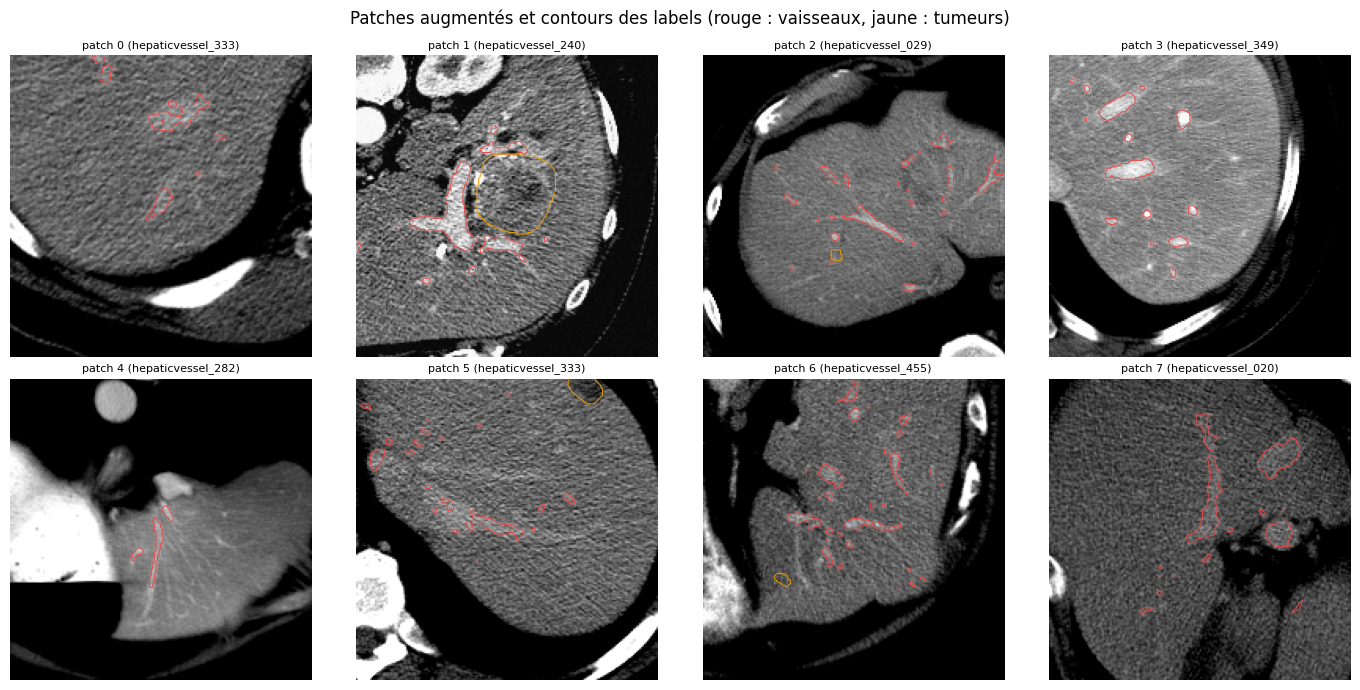

In [10]:
from src.data.dataset2d import PatchDataset2D
from src.preprocessing.intensity import background_value
base = load_config("configs/base_2d.yaml")
ds = PatchDataset2D(resolve(cfg["preprocessing"]["processed_dir"]), split["train"], 192, 8, 0.67,
                    background_value(stats), None, base["training"]["augmentation"], seed=0)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.ravel(), range(8)):
    s = ds[i]
    ax.imshow(s["image"][0], cmap="gray")
    ax.contour(s["label"].numpy() == 1, levels=[0.5], colors=["#e34948"], linewidths=0.7)
    ax.contour(s["label"].numpy() == 2, levels=[0.5], colors=["#eda100"], linewidths=0.7)
    ax.set_title(f"patch {i} ({ds.case_ids[s['case_idx']]})", fontsize=8); ax.axis("off")
plt.suptitle("Patches augmentés et contours des labels (rouge : vaisseaux, jaune : tumeurs)")
plt.tight_layout(); plt.show()

## Bilan

Les contrôles de chargement passent pour les 68 cas téléchargés, la séparation est bien disjointe au
niveau patient, et les patches augmentés restent alignés avec leurs masques. Les points à retenir
pour la suite sont la petite taille des vaisseaux (0,1 % des voxels), l'anisotropie des volumes et
la variabilité de l'espacement entre patients. Sur certaines coupes, des branches fines visibles ne
semblent pas annotées, ce qui limite la précision mesurable sur les petits vaisseaux.